Libraries & Parameters

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import matplotlib.pyplot as plt
import numpy as np
import os
import cv2

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
IMG_SIZE = 224
BATCH_SIZE = 32

DATASET_PATH = 'dataset'
IMAGE_FOLDER = 'images'

Data Loader

In [ ]:
train_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    os.path.join(DATASET_PATH, 'Training'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

validation_generator = test_datagen.flow_from_directory(
    os.path.join(DATASET_PATH, 'Testing'),
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

Found 8582 images belonging to 4 classes.
Found 1705 images belonging to 4 classes.


Feature Extraction

In [ ]:
def build_proposed_model():
    model = models.Sequential([
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.MaxPooling2D((2, 2)), 
        
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(len(CLASSES), activation='softmax')
    ])
    
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = build_proposed_model()

Modal Training

In [ ]:
history = model.fit(
    train_generator,
    epochs=15, 
    validation_data=validation_generator
)

Epoch 1/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 83s 302ms/step - accuracy: 0.7243 - loss: 0.6836 - val_accuracy: 0.7642 - val_loss: 0.8800
Epoch 2/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 82s 303ms/step - accuracy: 0.8684 - loss: 0.3309 - val_accuracy: 0.8188 - val_loss: 1.0240
Epoch 3/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 82s 304ms/step - accuracy: 0.9208 - loss: 0.2043 - val_accuracy: 0.8780 - val_loss: 0.8175
Epoch 4/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 81s 302ms/step - accuracy: 0.9509 - loss: 0.1359 - val_accuracy: 0.9009 - val_loss: 0.8896
Epoch 5/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 85s 316ms/step - accuracy: 0.9646 - loss: 0.0951 - val_accuracy: 0.9155 - val_loss: 1.0624
Epoch 6/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 78s 291ms/step - accuracy: 0.9734 - loss: 0.0740 - val_accuracy: 0.9114 - val_loss: 1.1114
Epoch 7/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 78s 290ms/step - accuracy: 0.9779 - loss: 0.0616 - val_accuracy: 0.9202 - val_loss: 1.2379
Epoch 8/15
269/269 ━━━━━━━━━━━━━━━━━━━━ 79s 292ms/step - accuracy: 0.9850 - loss: 0

Final Prediction

In [ ]:
def run_final_inference():
    """
    Performs prediction on the local 'images' folder and 
    prints results in English academic format.
    """
    print(f"{'Filename':<25} | {'Prediction':<15} | {'Confidence'}")
    print("-" * 60)
    
    for filename in os.listdir(IMAGE_FOLDER):
        if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
            path = os.path.join(IMAGE_FOLDER, filename)
            
            img = cv2.imread(path)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            img = img / 255.0
            img = np.expand_dims(img, axis=0)
            
            preds = model.predict(img, verbose=0)
            idx = np.argmax(preds)
            conf = np.max(preds) * 100
            
            print(f"{filename:<25} | {CLASSES[idx]:<15} | {conf:.2f}%")

run_final_inference()

Dosya Adı                 | Tahmin          | Güven Oranı
-------------------------------------------------------
2e24f3aafcb167efb067238d4347a5_big_gallery.jpg | notumor         | %100.00
37c04919c7379187058f8f88b55d8c_big_gallery.jpg | notumor         | %100.00
3b2d04f1204635db673f7066afa345_big_gallery.jpg | notumor         | %100.00
49255df18962ce81d979fb05f98ba1.jpg | meningioma      | %85.05
54264540dc90436314f93ac195056d_big_gallery.jpg | meningioma      | %99.89
73c54460c3e8d80f3d18cd522ed152_big_gallery.jpg | notumor         | %100.00
849c630e41db958c44af5d144d00fb_big_gallery.jpg | notumor         | %99.27
984ff33512e47ce91847de5e2af64a.jpg | notumor         | %100.00
a55634b4602b44d594a1f581b04cd187d0eb5040665b51841108f09825b757f6.png | pituitary       | %78.48
aef4f7cd9bed6546cd590e9a2bb659_big_gallery.jpg | notumor         | %93.86
cf06bd687c54fde6a333723118ab57.jpg | meningioma      | %63.94
cf4f7605011541042b803d17498f15.jpg | notumor         | %100.00
cfa088272fbb261117

Plotting Training History

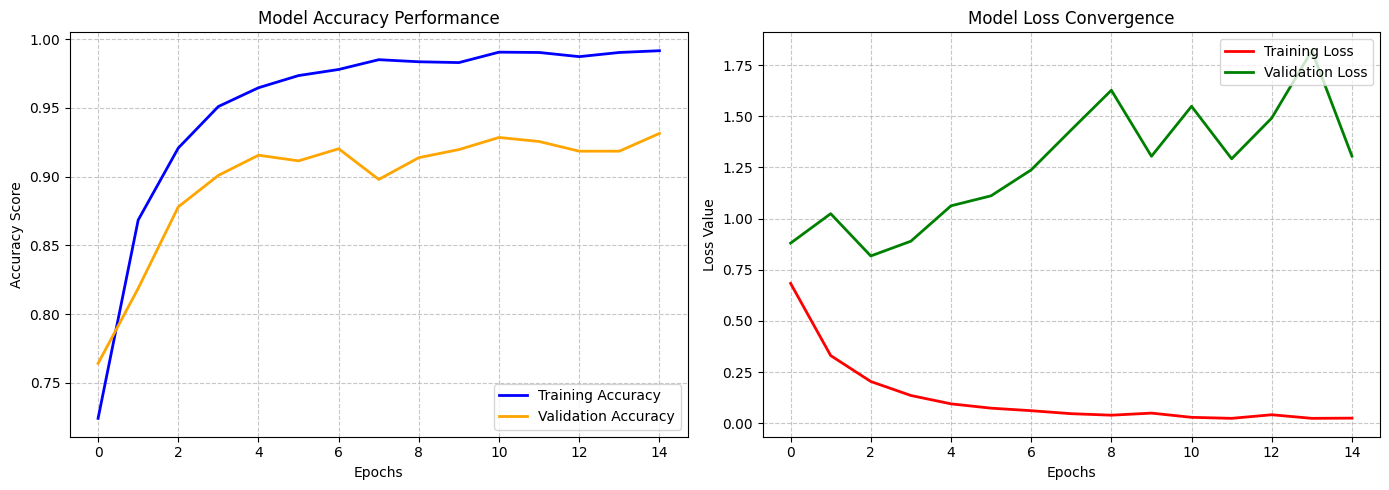

In [ ]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue', lw=2)
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', lw=2)
plt.title('Model Accuracy Performance')
plt.xlabel('Epochs')
plt.ylabel('Accuracy Score')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', color='red', lw=2)
plt.plot(history.history['val_loss'], label='Validation Loss', color='green', lw=2)
plt.title('Model Loss Convergence')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Confusion Matrix & Classification Report

Generating evaluation metrics...
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 92ms/step


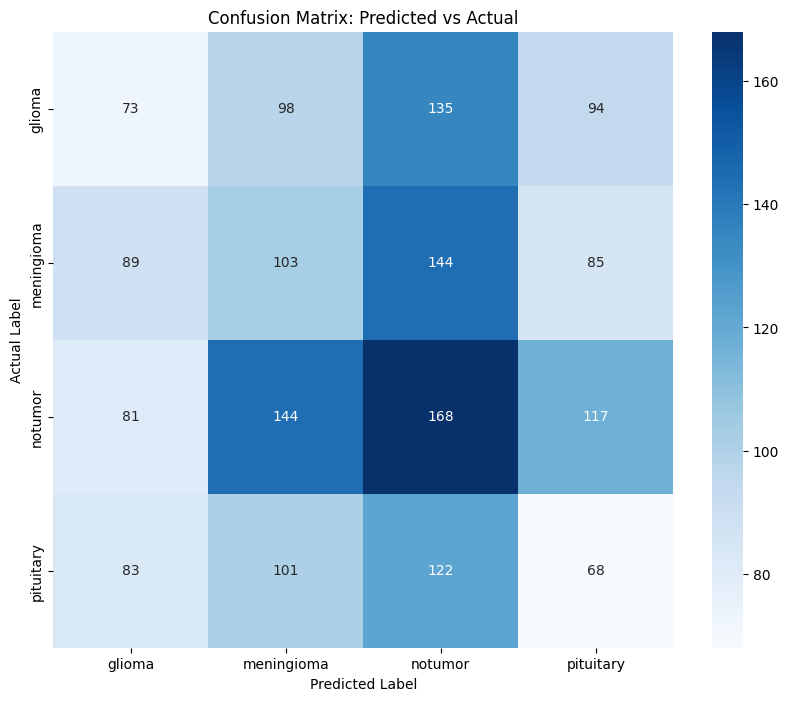


Classification Report:
              precision    recall  f1-score   support

      glioma       0.22      0.18      0.20       400
  meningioma       0.23      0.24      0.24       421
     notumor       0.30      0.33      0.31       510
   pituitary       0.19      0.18      0.18       374

    accuracy                           0.24      1705
   macro avg       0.23      0.23      0.23      1705
weighted avg       0.24      0.24      0.24      1705



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

print("Generating evaluation metrics...")
Y_pred = model.predict(validation_generator)
y_pred = np.argmax(Y_pred, axis=1)
y_true = validation_generator.classes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Confusion Matrix: Predicted vs Actual')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=CLASSES))

Visualizing Predictions with a Grid

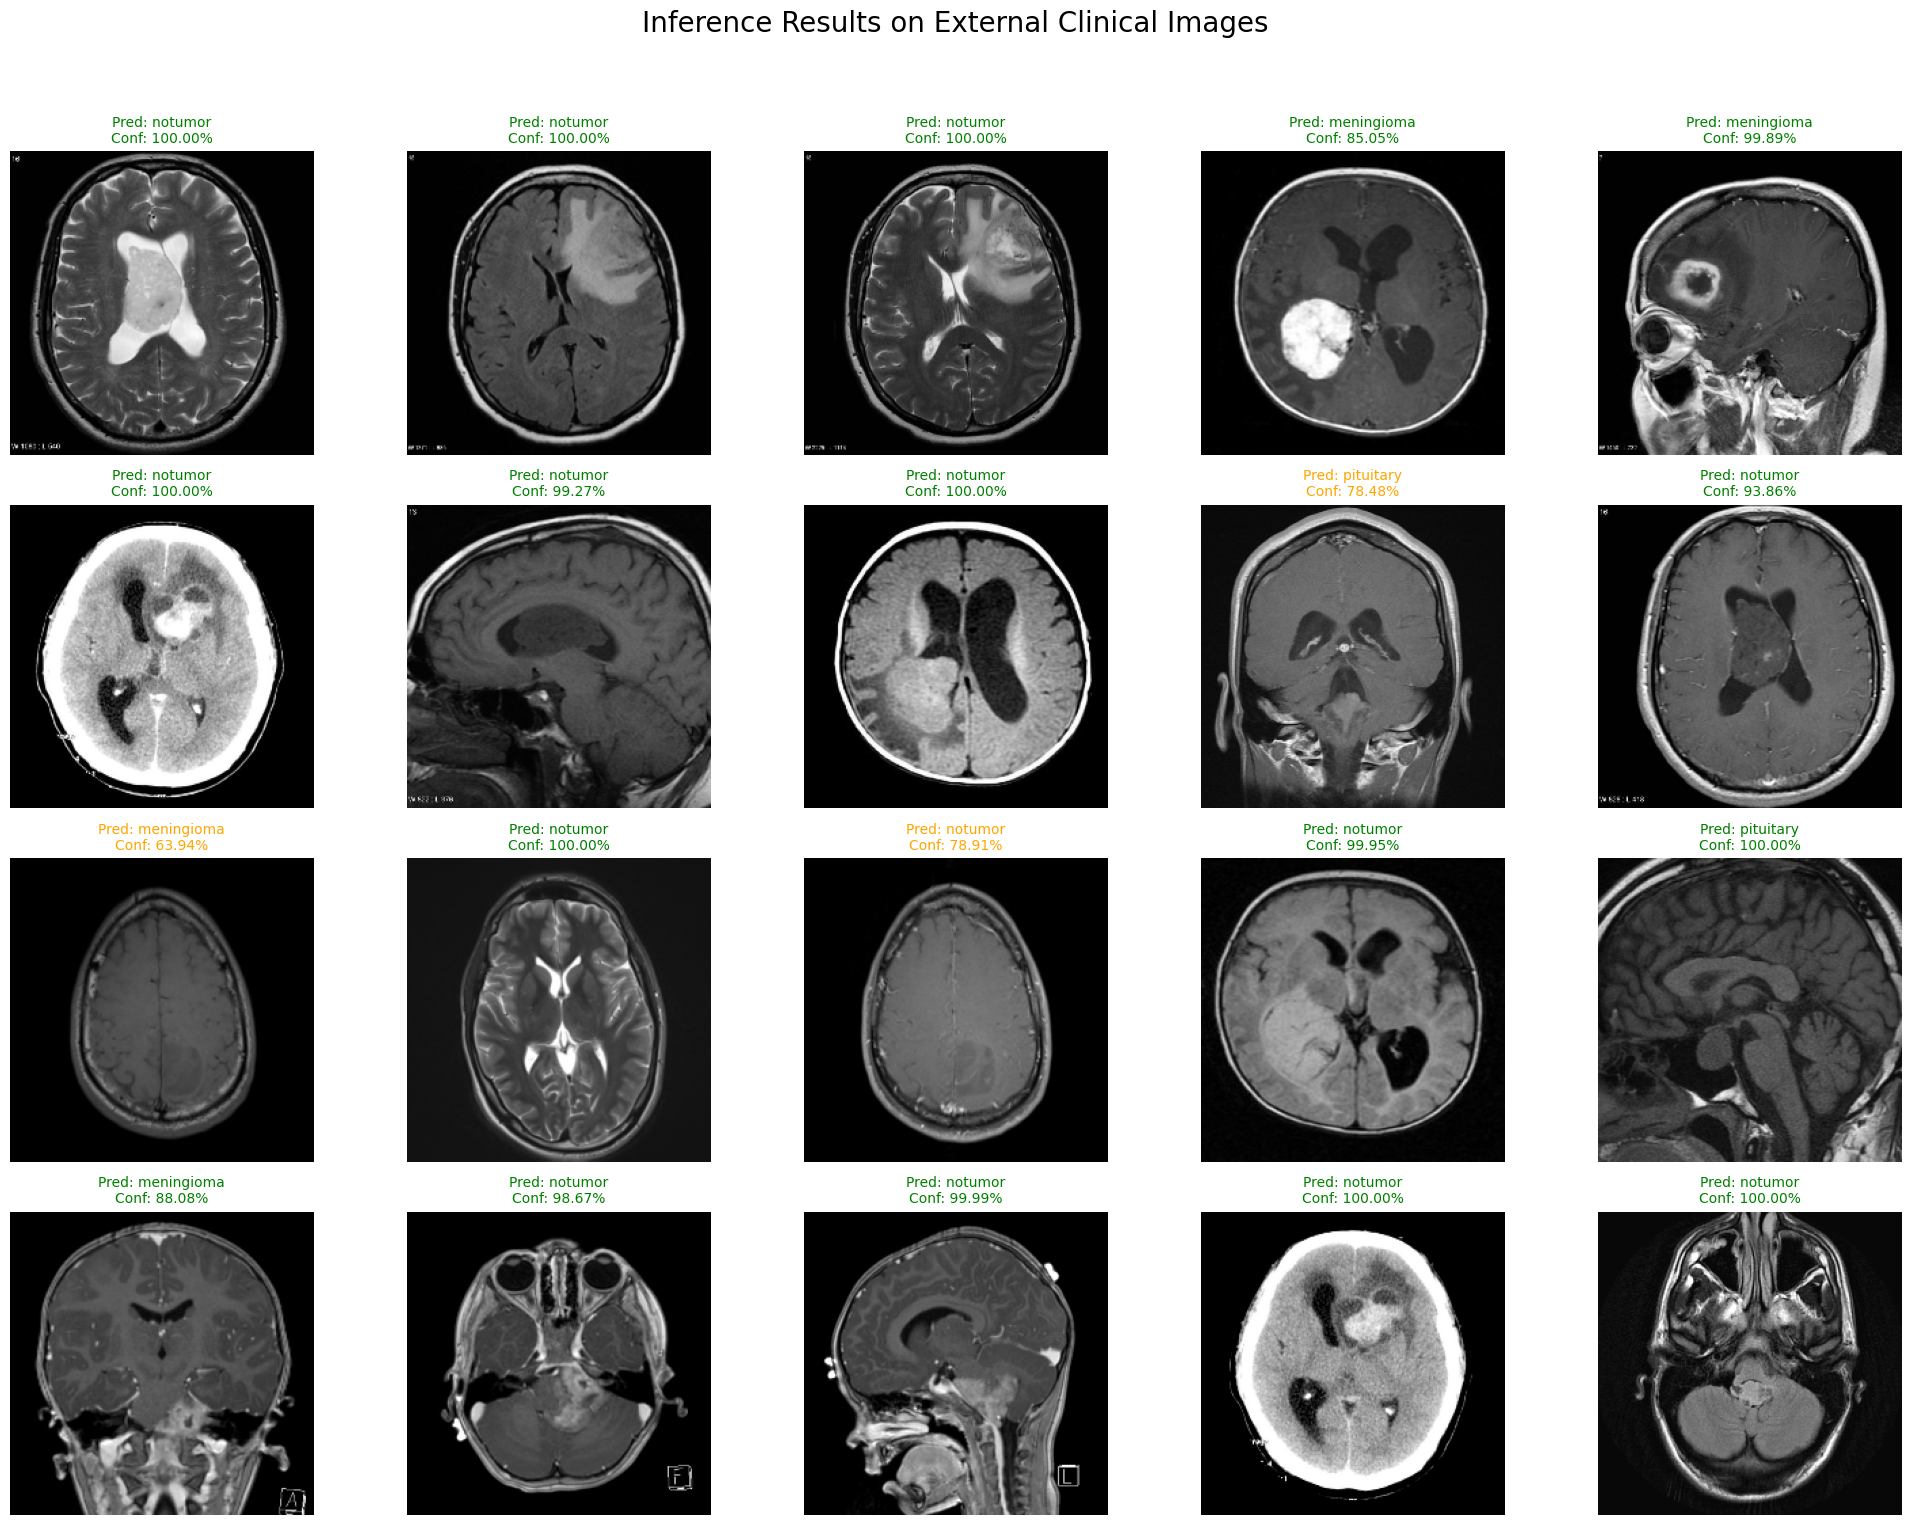

In [ ]:
import matplotlib.pyplot as plt

def visualize_test_results(folder_path, grid_rows=4, grid_cols=5):
    file_list = [f for f in os.listdir(folder_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    plt.figure(figsize=(20, 16))
    
    for i, filename in enumerate(file_list[:20]):
        path = os.path.join(folder_path, filename)
        
        raw_img = cv2.imread(path)
        img_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
        img_norm = img_resized / 255.0
        img_input = np.expand_dims(img_norm, axis=0)
        
        preds = model.predict(img_input, verbose=0)
        idx = np.argmax(preds)
        conf = np.max(preds) * 100
        
        plt.subplot(grid_rows, grid_cols, i + 1)
        plt.imshow(img_resized)
        
        title_color = 'green' if conf > 80 else 'orange'
        plt.title(f"Pred: {CLASSES[idx]}\nConf: {conf:.2f}%", color=title_color, fontsize=10)
        plt.axis('off')

    plt.suptitle("Inference Results on External Clinical Images", fontsize=20)
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

visualize_test_results(IMAGE_FOLDER)

Save Modal

In [31]:
model.save('brain_tumor_expert_model.keras')
print("Model saved successfully as .keras file!")

Model saved successfully as .keras file!
